In [19]:
# 1. Убедимся, что GPU на месте (после смены Runtime Type)
!nvidia-smi

# 2. Установим системные зависимости и Ollama
!sudo apt-get update -qq
!sudo apt-get install -y -qq zstd
!curl -fsSL https://ollama.com/install.sh | sh

# 3. Запустим сервер Ollama в фоне
!nohup ollama serve > ollama.log 2>&1 &

# 4. Дадим серверу пару секунд запуститься и проверим, что он жив
import time
time.sleep(5)
!ollama list

Wed Oct 28 07:19:38 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   73C    P0             33W /   70W |    6419MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [20]:
# Скачиваем модель. Для T4 16GB VRAM этого более чем достаточно.
!ollama pull qwen2.5:7b

# Проверяем, что модель загрузилась
!ollama list


NAME          ID              SIZE      MODIFIED               
qwen2.5:7b    845dbda0ea48    4.7 GB    Less than a second ago    


In [21]:
import os, re, json, zipfile, requests, time, pickle
from pathlib import Path
from typing import List, Optional, Tuple
import numpy as np
import faiss
from sentence_transformers import SentenceTransformer, CrossEncoder
from huggingface_hub import list_repo_files
from tqdm.auto import tqdm
from langchain_ollama import ChatOllama

# ---------- КОНФИГ ----------
# Для TechQA используем сильную мультиязычную модель, которая отлично работает на GPU
EMBEDDER_NAME = "BAAI/bge-base-en-v1.5"

CHUNK_SIZE    = 1000          # Можно увеличить, т.к. T4 быстрый
CHUNK_OVERLAP = 150

TOP_K         = 10
SIM_THRESHOLD = 0.75          # Для TechQA (is_impossible) порог почти не работает, но пусть будет
KEEP_RATIO    = 0.85
MAX_CONTEXT_CHARS = 6000      # Увеличиваем, т.к. контекстное окно LLM больше

# ---------- OLLAMA / LLM ----------
OLLAMA_MODEL          = "qwen2.5:7b"
OLLAMA_NUM_CTX        = 8192   # Увеличиваем контекст, памяти хватает
OLLAMA_NUM_GPU        = -1     # -1 = использовать все слои на GPU
OLLAMA_REPEAT_PENALTY = 1.1
OLLAMA_NUM_PREDICT    = 800

# ---------- NLI ----------
NLI_MODEL_NAME = "cross-encoder/nli-deberta-v3-base"

REFUSAL_PHRASE_EN = ("I cannot answer this question because the provided documents "
                     "do not contain the necessary information.")
REFUSAL_PHRASE = REFUSAL_PHRASE_EN

In [22]:
DATA_DIR = Path("techqa_data")
DATA_DIR.mkdir(exist_ok=True)
CORPUS_DIR = DATA_DIR / "corpus"
CORPUS_DIR.mkdir(exist_ok=True)

BASE_URL = "https://huggingface.co/datasets/nvidia/TechQA-RAG-Eval/resolve/main/"

# Скачиваем train.json
train_path = DATA_DIR / "train.json"
if not train_path.exists():
    print("Скачиваем train.json...")
    r = requests.get(BASE_URL + "train.json", timeout=60)
    r.raise_for_status()
    train_path.write_bytes(r.content)
    print(f"✅ train.json: {train_path.stat().st_size / 1024:.1f} KB")

# Скачиваем corpus.zip
zip_path = DATA_DIR / "corpus.zip"
if not zip_path.exists():
    print("Скачиваем corpus.zip (~46 MB)...")
    r = requests.get(BASE_URL + "corpus.zip", timeout=300, stream=True)
    r.raise_for_status()
    total = int(r.headers.get("content-length", 0))
    with open(zip_path, "wb") as f, tqdm(total=total, unit="B", unit_scale=True, desc="corpus.zip") as pbar:
        for chunk in r.iter_content(chunk_size=8192):
            f.write(chunk)
            pbar.update(len(chunk))

# Распаковываем
if not any(CORPUS_DIR.iterdir()):
    print("Распаковываем корпус...")
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(CORPUS_DIR)

# Загружаем train.json
with open(train_path, "r", encoding="utf-8") as f:
    train_data = json.load(f)
print(f"Загружено вопросов: {len(train_data)}")

Загружено вопросов: 910


In [14]:
documents, doc_names = [], []
for txt_file in sorted(CORPUS_DIR.rglob("*.txt")):
    try:
        text = txt_file.read_text(encoding="utf-8", errors="ignore")
        text = re.sub(r'\s+', ' ', text).strip()
        if len(text) > 100:
            documents.append(text)
            doc_names.append(str(txt_file.relative_to(CORPUS_DIR)))
    except Exception as e:
        print(f"⚠️ Пропущен {txt_file.name}: {e}")

print(f"Загружено документов: {len(documents)}")

def chunk_text(text: str, chunk_size: int = CHUNK_SIZE, overlap: int = CHUNK_OVERLAP) -> List[str]:
    chunks, start = [], 0
    while start < len(text):
        end = min(start + chunk_size, len(text))
        chunk = text[start:end].strip()
        if len(chunk) > 50:
            chunks.append(chunk)
        start += chunk_size - overlap
    return chunks

def clean_text(text: str) -> str:
    """Убирает markdown-артефакты парсинга (* * , **, одиночные *)."""
    text = re.sub(r'\*\s*\*', ' ', text)
    text = re.sub(r'\*+', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

all_chunks, chunk_metadata = [], []
for doc_name, doc_text in zip(doc_names, documents):
    for i, chunk in enumerate(chunk_text(doc_text)):
        cleaned = clean_text(chunk)
        if len(cleaned) > 50:
            all_chunks.append(cleaned)
            chunk_metadata.append({"doc_name": doc_name, "chunk_index": i})

print(f"Всего чанков после очистки: {len(all_chunks)}")

Загружено документов: 28481
Всего чанков после очистки: 127040


In [15]:
EMB_CACHE_PATH = Path("techqa_chunk_embeddings_bge_base.pkl")

# T4 GPU доступен, поэтому устройство будет "cuda"
# Было:
# embedder = SentenceTransformer(EMBEDDER_NAME, device="cuda" if os.environ.get("CUDA_VISIBLE_DEVICES") else "cpu")

# Стало:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
embedder = SentenceTransformer(EMBEDDER_NAME, device=device)
print(f"Модель: {EMBEDDER_NAME} | устройство: {embedder.device}")
print(f"torch.cuda.is_available() = {torch.cuda.is_available()}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'нет'}")

assert embedder.device.type == "cuda", \
    "⚠️ Модель на CPU — проверьте, что Runtime → Change runtime type → T4 GPU"
print(f"Модель: {EMBEDDER_NAME} | устройство: {embedder.device}")

cached = None
if EMB_CACHE_PATH.exists():
    with open(EMB_CACHE_PATH, "rb") as f:
        cached = pickle.load(f)
    ok = (cached.get("num_chunks") == len(all_chunks)
          and cached.get("embedder_name") == EMBEDDER_NAME)
    if ok:
        print(f"✅ Кэш валиден: shape={cached['embeddings'].shape}")
    else:
        cached = None

if cached is None:
    # bge-m3 не требует префиксов, но для симметрии можно оставить
    texts = all_chunks

    # Замер на маленькой порции (быстро на GPU)
    probe = min(32, len(texts))
    _ = embedder.encode(texts[:probe], normalize_embeddings=True, batch_size=32)
    t0 = time.time()
    _ = embedder.encode(texts[:probe], normalize_embeddings=True, batch_size=32)
    per = (time.time() - t0) / probe
    print(f"⏱️ ~{per*1000:.1f} мс/чанк → оценка: ~{per * len(texts) / 60:.1f} мин")

    t0 = time.time()
    chunk_embeddings = embedder.encode(
        texts,
        normalize_embeddings=True,
        convert_to_numpy=True,
        batch_size=64,          # На GPU можно и больше
        show_progress_bar=True,
    )
    print(f"✅ Готово за {(time.time()-t0)/60:.1f} мин")

    with open(EMB_CACHE_PATH, "wb") as f:
        pickle.dump({
            "num_chunks": len(all_chunks),
            "embedder_name": EMBEDDER_NAME,
            "embeddings": chunk_embeddings,
        }, f)
    print(f"💾 Сохранено в {EMB_CACHE_PATH}")
else:
    chunk_embeddings = cached["embeddings"]

# FAISS
t0 = time.time()
index = faiss.IndexFlatIP(chunk_embeddings.shape[1])
index.add(chunk_embeddings.astype("float32"))
print(f"✅ FAISS за {time.time()-t0:.2f} с: {index.ntotal} векторов")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Модель: BAAI/bge-base-en-v1.5 | устройство: cuda:0
torch.cuda.is_available() = True
GPU: Tesla T4
Модель: BAAI/bge-base-en-v1.5 | устройство: cuda:0
⏱️ ~21.2 мс/чанк → оценка: ~44.8 мин


Batches:   0%|          | 0/1985 [00:00<?, ?it/s]

✅ Готово за 57.2 мин
💾 Сохранено в techqa_chunk_embeddings_bge_base.pkl
✅ FAISS за 0.65 с: 127040 векторов


In [23]:
def retrieve(query: str, top_k: int = TOP_K,
             threshold: float = SIM_THRESHOLD,
             keep_ratio: float = KEEP_RATIO,
             max_chars: int = MAX_CONTEXT_CHARS
             ) -> Tuple[Optional[List[str]], Optional[List[dict]], float]:
    q_emb = embedder.encode(
        [query],
        normalize_embeddings=True, convert_to_numpy=True,
    ).astype("float32")

    scores, idxs = index.search(q_emb, top_k)
    scores, idxs = scores[0], idxs[0]
    best = float(scores[0])

    if best < threshold:
        return None, None, best

    kept_chunks, kept_meta, total = [], [], 0
    for score, idx in zip(scores, idxs):
        if score < best * keep_ratio:
            continue
        c = all_chunks[idx]
        if total + len(c) > max_chars and kept_chunks:
            break
        kept_chunks.append(c)
        kept_meta.append(chunk_metadata[idx])
        total += len(c)
    return kept_chunks, kept_meta, best

In [40]:
# =====================================================================
# 1. ИНИЦИАЛИЗАЦИЯ LLM (теперь на GPU!)
# =====================================================================
llm = ChatOllama(
    model=OLLAMA_MODEL,
    temperature=0.1,
    num_ctx=OLLAMA_NUM_CTX,
    num_gpu=OLLAMA_NUM_GPU,        # -1 = все слои на GPU
    repeat_penalty=OLLAMA_REPEAT_PENALTY,
    num_predict=OLLAMA_NUM_PREDICT,
    base_url="http://localhost:11434",
)

try:
    probe = llm.invoke("Reply with one word only: ready").content.strip()
    print(f"✅ LLM доступна. Тест: {probe!r}")
except Exception as e:
    print(f"❌ LLM недоступна: {e}")

# =====================================================================
# 2. ИНИЦИАЛИЗАЦИЯ NLI
# =====================================================================
NLI_AVAILABLE = False
_nli_entail_idx = 1
_nli_contradict_idx = 0

try:
    nli_model = CrossEncoder(NLI_MODEL_NAME, device=device)
    _labels = nli_model.model.config.id2label
    _nli_entail_idx = next((i for i, l in _labels.items() if 'entail' in l.lower()), 1)
    _nli_contradict_idx = next((i for i, l in _labels.items() if 'contradict' in l.lower()), 0)
    NLI_AVAILABLE = True
    print(f"✅ NLI загружена: entail_idx={_nli_entail_idx}, contradict_idx={_nli_contradict_idx}")
except Exception as e:
    print(f"⚠️ NLI недоступна: {e}")

# =====================================================================
# 3. ПРОМПТ С ОБЯЗАТЕЛЬНОЙ ЦИТАТОЙ
# =====================================================================
SYSTEM_PROMPT = """You are a strict technical support assistant.
Answer ONLY based on the provided CONTEXT. Answer in English.
Before answering, you MUST find a specific sentence in the context that directly supports your answer.
If no such sentence exists, you MUST refuse."""

def _build_prompt(query: str, context: str) -> str:
    return f"""{SYSTEM_PROMPT}

CONTEXT:
{context}

QUESTION: {query}

INSTRUCTIONS:
1. First, find and quote the EXACT sentence from the context that supports the answer.
2. If you cannot find such a sentence, respond EXACTLY:
   REFUSAL: {REFUSAL_PHRASE}
3. Otherwise, respond in this format:
   SUPPORT: "<exact sentence from context>"
   ANSWER: <your answer in 1-3 sentences>

Your response:"""

# =====================================================================
# 4. ХЕЛПЕРЫ
# =====================================================================
def _normalize(s: str) -> str:
    return re.sub(r'\s+', ' ', s.lower().strip())

def _looks_like_refusal(answer: str) -> bool:
    a = answer.strip().lower()
    if len(a) > 300:
        return False
    return (
        "cannot answer" in a
        or "do not contain" in a
        or "no necessary information" in a
        or "refusal:" in a[:20]
    ) and not any(w in a for w in ["however", "but ", "nevertheless", "according to"])

def strip_markdown(text: str) -> str:
    text = re.sub(r'\*\*(.+?)\*\*', r'\1', text)
    text = re.sub(r'(?<!\*)\*(?!\*)(.+?)(?<!\*)\*(?!\*)', r'\1', text)
    text = re.sub(r'`(.+?)`', r'\1', text)
    return text

def dedupe_repeated_lines(text: str, max_dupes: int = 1) -> str:
    seen, result = {}, []
    for line in text.split("\n"):
        key = line.strip().lower()
        if not key:
            result.append(line); continue
        seen[key] = seen.get(key, 0) + 1
        if seen[key] <= max_dupes:
            result.append(line)
    return "\n".join(result)

def answer_is_clean(answer: str) -> Tuple[bool, str]:
    if _looks_like_refusal(answer):
        return True, ""
    if re.search(r'[\u4e00-\u9fff\u3040-\u30ff\uac00-\ud7af]', answer):
        return False, "восточноазиатские символы"
    # Underscore ловим только при наличии кириллицы рядом
    if re.search(r'[А-Яа-яЁё]+_\w+|\w+_[А-Яа-яЁё]+', answer):
        return False, "underscore внутри слов с кириллицей"
    # Фейковые номера — только 5+ уровней
    if re.search(r'\b\d+(?:\.\d+){5,}\b', answer):
        return False, "фейковые многоуровневые номера"
    return True, ""

def _support_is_in_context(support: str, context: str, min_word_overlap: float = 0.70) -> bool:
    if len(support) < 20:
        return False
    s_norm = _normalize(support).strip('"\'').strip()
    c_norm = _normalize(context)
    if s_norm in c_norm:
        return True
    s_words = {w for w in re.findall(r'\w+', s_norm) if len(w) > 3}
    if not s_words:
        return False
    c_words = set(re.findall(r'\w+', c_norm))
    overlap = len(s_words & c_words) / len(s_words)
    return overlap >= min_word_overlap

from scipy.special import softmax

def answer_is_grounded_nli(answer: str, support: str,
                           context: str = "",
                           debug: bool = False) -> Tuple[bool, str]:
    """
    Проверяет, не противоречит ли ответ контексту.

    Логика:
    - SUPPORT от LLM — это узкая цитата, ответ часто шире неё.
    - Сравниваем ответ с ПОЛНЫМ контекстом (там все детали).
    - Отклоняем ТОЛЬКО при явном противоречии (contradict > 0.5).
    - Нейтральность (entail низкий, contradict низкий) НЕ наказуема.
    """
    if not NLI_AVAILABLE or _looks_like_refusal(answer):
        return True, ""

    # ⚠️ Полный контекст, а не узкий SUPPORT
    premise = context if context and len(context) > 100 else support
    if not premise or len(premise) < 50:
        return False, "empty_premise"

    sents = [s.strip() for s in re.split(r'(?<=[.!?])\s+', answer)
             if len(s.strip()) > 15]
    if not sents:
        return True, ""

    pairs = [(premise, s) for s in sents]
    logits = nli_model.predict(pairs)
    probs = softmax(logits, axis=1)

    contradictions = []
    for s, pr in zip(sents, probs):
        e = float(pr[_nli_entail_idx])
        c = float(pr[_nli_contradict_idx])
        if debug:
            print(f"  NLI(ctx): entail={e:.3f}, contradict={c:.3f} | {s[:80]}...")
        # ⚠️ только явное противоречие
        if c > 0.5:
            contradictions.append(s)

    if contradictions:
        return False, f"{len(contradictions)}/{len(sents)} предложений противоречат контексту"
    return True, ""

def llm_self_verify(query: str, context: str, answer: str) -> Tuple[bool, str]:
    """
    Мягкая версия: спрашиваем, ПРОТИВОРЕЧИТ ли ответ контексту,
    а не «содержится ли он явно». Противоречие — единственный
    надёжный сигнал для 7B-модели.
    """
    verify_prompt = f"""Does the proposed answer CONTRADICT the context, or does it merely go beyond it?

CONTEXT:
{context[:3000]}

QUESTION: {query}

PROPOSED ANSWER: {answer}

Rules:
- If the answer says something the context says is FALSE → reply CONTRADICTS
- If the answer is reasonable but not explicitly stated → reply EXTENDS
- If the answer is directly supported → reply SUPPORTS

Reply with exactly one word: CONTRADICTS, EXTENDS, or SUPPORTS."""

    try:
        verdict = llm.invoke(verify_prompt).content.strip().upper()
        head = verdict[:20]
        # Отклоняем ТОЛЬКО при явном противоречии
        if "CONTRADICT" in head:
            return False, verdict[:50]
        return True, verdict[:50]
    except Exception as e:
        return True, f"[verify error: {e}]"

# =====================================================================
# 5. ОСНОВНАЯ ФУНКЦИЯ ГЕНЕРАЦИИ
# =====================================================================
def _refusal_result(best_score, meta, reason, raw=""):
    return {
        "answer": REFUSAL_PHRASE, "refused": True,
        "best_score": best_score, "sources": meta,
        "refusal_reason": reason, "raw_answer": raw,
    }

def generate_answer(query: str, debug: bool = False) -> dict:
    chunks, meta, best_score = retrieve(query)
    if chunks is None:
        return _refusal_result(best_score, [], "low_relevance")

    context = "\n\n---\n\n".join(chunks)
    prompt = _build_prompt(query, context)

    try:
        raw = llm.invoke(prompt).content.strip()
    except Exception as e:
        return {
            "answer": f"[LLM error: {e}]", "refused": False,
            "best_score": best_score, "sources": meta,
            "refusal_reason": "llm_error", "raw_answer": "",
        }

    if debug:
        print(f"  RAW: {raw[:300]}")

    if _looks_like_refusal(raw):
        return _refusal_result(best_score, meta, "llm_refused", raw)

    if "ANSWER:" not in raw:
        return _refusal_result(best_score, meta, "no_answer_format", raw)

    parts = raw.split("ANSWER:", 1)
    pre, answer = parts[0], parts[1].strip()
    support = ""
    if "SUPPORT:" in pre:
        support = pre.split("SUPPORT:", 1)[1].strip()

    if not support:
        return _refusal_result(best_score, meta, "missing_support", raw)

    if not _support_is_in_context(support, context):
        return _refusal_result(best_score, meta, "fabricated_support", raw)

    answer = strip_markdown(answer)
    answer = dedupe_repeated_lines(answer)

    if _looks_like_refusal(answer):
        return _refusal_result(best_score, meta, "llm_refused", raw)

    ok, reason = answer_is_clean(answer)
    if not ok:
        return _refusal_result(best_score, meta, f"dirty:{reason}", raw)

    ok, reason = answer_is_grounded_nli(answer, support, context=context, debug=debug)
    if not ok:
        return _refusal_result(best_score, meta, f"ungrounded:{reason}", raw)

    # Guardrail #6: LLM self-verification — ОТКЛЮЧЕНО
    # verified, verdict = llm_self_verify(query, context, answer)
    # if not verified:
    #     return _refusal_result(best_score, meta, f"llm_contradicts:{verdict}", raw)

    return {
        "answer": answer, "refused": False,
        "best_score": best_score, "sources": meta,
        "refusal_reason": "", "raw_answer": raw,
        "support": support,
    }

✅ LLM доступна. Тест: 'Ready'


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

✅ NLI загружена: entail_idx=1, contradict_idx=0


In [41]:
def evaluate_techqa(n_samples: int = 20):
    answerable = [q for q in train_data if not q.get("is_impossible", False)]
    impossible = [q for q in train_data if q.get("is_impossible", False)]

    print(f"Всего answerable: {len(answerable)}, impossible: {len(impossible)}")

    print("\n--- ANSWERABLE ---")
    correct_answers = 0
    for item in tqdm(answerable[:n_samples], desc="answerable"):
        res = generate_answer(item["question"])
        if not res["refused"]:
            correct_answers += 1

    print("\n--- IMPOSSIBLE ---")
    correct_refusals = 0
    for item in tqdm(impossible[:n_samples], desc="impossible"):
        res = generate_answer(item["question"])
        if res["refused"]:
            correct_refusals += 1

    total_a = min(n_samples, len(answerable))
    total_i = min(n_samples, len(impossible))

    print(f"\n{'='*50}")
    print(f"Answerable:  {correct_answers}/{total_a} дали ответ (не отказ)")
    print(f"Impossible:  {correct_refusals}/{total_i} корректно отказали")
    if total_i > 0:
        print(f"Точность на impossible: {correct_refusals/total_i*100:.1f}%")
    print(f"{'='*50}")

evaluate_techqa(n_samples=20)

Всего answerable: 610, impossible: 300

--- ANSWERABLE ---


answerable:   0%|          | 0/20 [00:00<?, ?it/s]


--- IMPOSSIBLE ---


impossible:   0%|          | 0/20 [00:00<?, ?it/s]


Answerable:  12/20 дали ответ (не отказ)
Impossible:  12/20 корректно отказали
Точность на impossible: 60.0%


In [42]:
from collections import Counter

def diagnose(n: int = 5):
    answerable = [q for q in train_data if not q.get("is_impossible", False)]
    reasons = Counter()
    print(f"\n{'='*70}\nДИАГНОСТИКА {n} ANSWERABLE ВОПРОСОВ\n{'='*70}")
    for item in answerable[:n]:
        q = item["question"]
        print(f"\n❓ {q[:150]}")
        res = generate_answer(q, debug=True)
        status = "REFUSED" if res["refused"] else "ANSWERED ✅"
        print(f"   → {status} | reason: {res['refusal_reason']}")
        reasons[res["refusal_reason"]] += 1
        if res["refused"]:
            print(f"   → raw LLM: {res.get('raw_answer','')[:250]}")

    print(f"\n{'='*70}\nРАСПРЕДЕЛЕНИЕ ПРИЧИН:\n{'='*70}")
    for r, c in reasons.most_common():
        print(f"  {r:30s}: {c}")
    print("\nℹ️ Расшифровка:")
    print("  llm_refused          → модель сама отказалась (промпт слишком строгий)")
    print("  no_answer_format     → LLM не выдала SUPPORT/ANSWER")
    print("  missing_support      → SUPPORT пустой")
    print("  fabricated_support   → SUPPORT не найден в контексте (over-strict)")
    print("  ungrounded:...       → NLI отклонила (over-strict)")
    print("  llm_verify_failed    → второй вызов LLM сказал NO (over-strict)")
    print("  dirty:...            → артефакты в ответе")

diagnose(n=5)


ДИАГНОСТИКА 5 ANSWERABLE ВОПРОСОВ

❓ User environment variables no longer getting picked up after upgrade to 4.1.1.1 or 4.1.1.2?



Have you found that after upgrade to Streams 4.1.1.1 or
  RAW: SUPPORT: "When running Streams as a system service with Streams releases 4.1.1.1 or 1.1.2, toolkits and user applications that depend on the user environment may have various errors. For example the database toolkit might show the following error if it does not pick up the ODBCINI environment variab
  NLI(ctx): entail=0.001, contradict=0.000 | Yes, after upgrading to Streams 4.1.1.1 or 4.1.1.2, environment variables set in...
   → ANSWERED ✅ | reason: 

❓ Netcool/Impact (all versions): How is the Exit() action function expected to work with User Defined Functions?

Netcool/Impact (all versions)

Using t
  RAW: SUPPORT: "Using the Exit() parser function within a User Defined (or Custom) Function in Impact Policy Language (IPL) will not exit the Policy process, it will only exit the User Defined

Прогоняем 30 answerable + 30 impossible...


answerable:   0%|          | 0/30 [00:00<?, ?it/s]

impossible:   0%|          | 0/30 [00:00<?, ?it/s]

/tmp/ipykernel_517/1787474792.py:126: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_517/1787474792.py:126: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


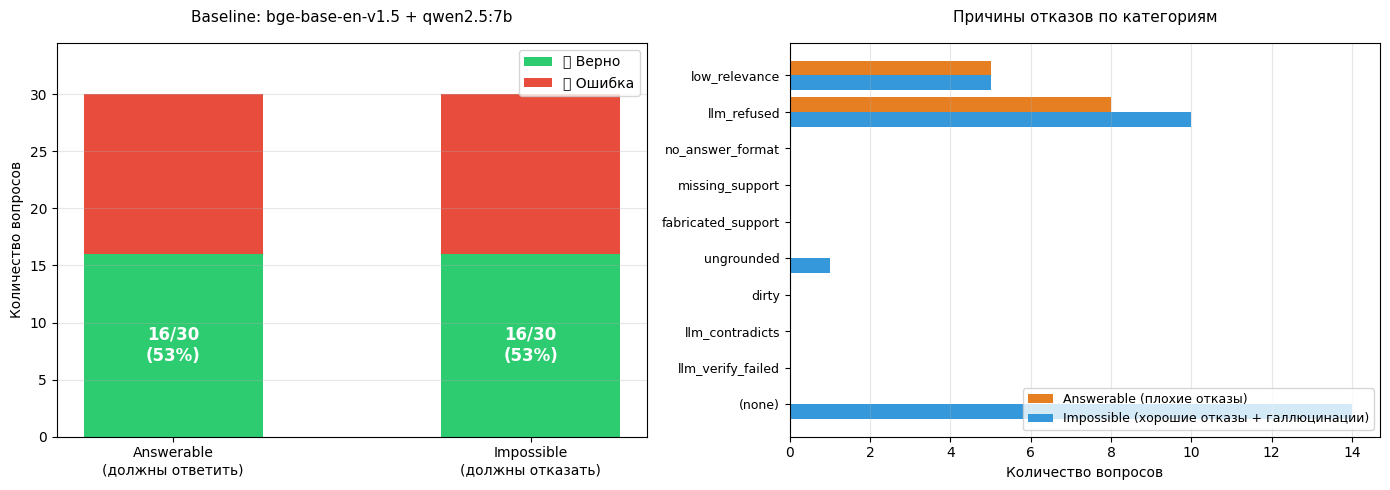


РЕЗУЛЬТАТ BASELINE (n=30 в каждой категории)
  Answerable (дали ответ):  16/30  (53.3%)
  Impossible (отказали):    16/30  (53.3%)
  Средний баланс:           53.3%


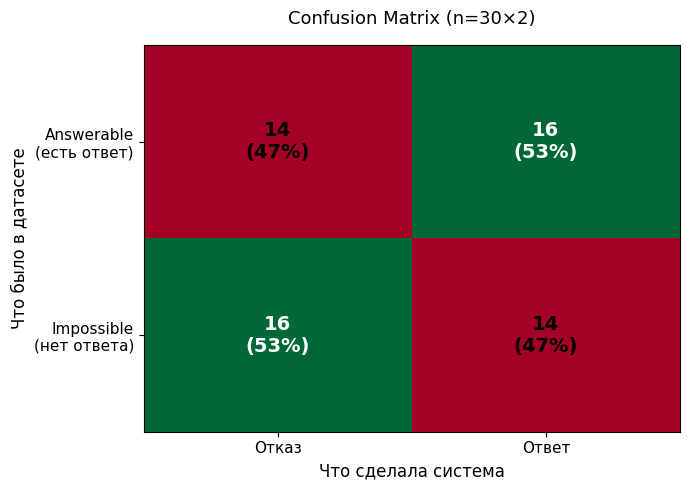


💡 Как читать матрицу:
  Верхняя левая  (14):  ЛОЖНЫЙ ОТКАЗ — плохо (не ответили, хотя могли)
  Верхняя правая (16):  ПРАВИЛЬНО — ответили на answerable ✅
  Нижняя левая   (16):  ПРАВИЛЬНО — отказали на impossible ✅
  Нижняя правая  (14):  ГАЛЛЮЦИНАЦИЯ — плохо (ответили, хотя ответа нет)


In [43]:
import matplotlib.pyplot as plt
import numpy as np
import json
from datetime import datetime
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report
from tqdm.auto import tqdm

# ============================================================
# 1. Прогоняем более широкую выборку для честных метрик
# ============================================================
N_EVAL = 30   # было 20; для визуализации 30 нагляднее, но всё ещё быстро (~2 мин)

answerable = [q for q in train_data if not q.get("is_impossible", False)]
impossible = [q for q in train_data if q.get("is_impossible", False)]

print(f"Прогоняем {N_EVAL} answerable + {N_EVAL} impossible...")

results_ans, results_imp = [], []
for item in tqdm(answerable[:N_EVAL], desc="answerable"):
    r = generate_answer(item["question"])
    results_ans.append({
        "question": item["question"][:200],
        "refused": r["refused"],
        "reason": r["refusal_reason"],
        "best_score": r["best_score"],
        "answer": r["answer"][:300],
        "raw": r.get("raw_answer", "")[:300],
    })

for item in tqdm(impossible[:N_EVAL], desc="impossible"):
    r = generate_answer(item["question"])
    results_imp.append({
        "question": item["question"][:200],
        "refused": r["refused"],
        "reason": r["refusal_reason"],
        "best_score": r["best_score"],
        "answer": r["answer"][:300],
        "raw": r.get("raw_answer", "")[:300],
    })

# ============================================================
# 2. Метрики
# ============================================================
# Для answerable: "правильно" = не отказ (система ответила)
# Для impossible: "правильно" = отказ (система не сгаллюцинировала)
tp_ans = sum(1 for r in results_ans if not r["refused"])   # ответил на answerable
tp_imp = sum(1 for r in results_imp if r["refused"])       # отказал на impossible

answerable_rate = tp_ans / N_EVAL * 100
impossible_rate = tp_imp / N_EVAL * 100

# ============================================================
# 3. Визуализация
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- График 1: Bar chart по двум категориям ---
ax = axes[0]
categories = ["Answerable\n(должны ответить)", "Impossible\n(должны отказать)"]
correct   = [tp_ans, tp_imp]
incorrect = [N_EVAL - tp_ans, N_EVAL - tp_imp]

x = np.arange(2)
width = 0.5
bars1 = ax.bar(x, correct,   width, label="✅ Верно",  color="#2ecc71")
bars2 = ax.bar(x, incorrect, width, bottom=correct, label="❌ Ошибка", color="#e74c3c")

ax.set_ylabel("Количество вопросов")
ax.set_title(f"Baseline: {EMBEDDER_NAME.split('/')[-1]} + {OLLAMA_MODEL}",
             fontsize=11, pad=15)
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0, N_EVAL * 1.15)
ax.legend(loc="upper right")
ax.grid(axis="y", alpha=0.3)

# Подписи процентов на барах
for i, (c, t) in enumerate(zip(correct, [tp_ans, tp_imp])):
    pct = c / N_EVAL * 100
    ax.text(i, c / 2, f"{c}/{N_EVAL}\n({pct:.0f}%)",
            ha="center", va="center", fontweight="bold", color="white", fontsize=12)

# --- График 2: Распределение причин отказов ---
ax = axes[1]
from collections import Counter

# Причины отказов на answerable (плохие отказы)
ans_reasons = Counter(r["reason"] for r in results_ans if r["refused"])
# Причины отказов на impossible (хорошие отказы)
imp_reasons = Counter(r["reason"] for r in results_imp if r["refused"])
# Причины ответов на impossible (плохие ответы — галлюцинации)
imp_answered = sum(1 for r in results_imp if not r["refused"])

# Составляем данные для stacked bar
reason_labels = ["low_relevance", "llm_refused", "no_answer_format",
                 "missing_support", "fabricated_support", "ungrounded",
                 "dirty", "llm_contradicts", "llm_verify_failed", "(none)"]

ans_by_reason = [ans_reasons.get(lbl.split(":")[0], 0) if lbl != "(none)" else 0
                 for lbl in reason_labels]
imp_by_reason = []
for lbl in reason_labels:
    if lbl == "(none)":
        imp_by_reason.append(imp_answered)  # ответы на impossible = галлюцинации
    else:
        # суммируем по префиксу (reason может содержать ":...")
        cnt = sum(v for k, v in imp_reasons.items() if k.split(":")[0] == lbl)
        imp_by_reason.append(cnt)

# Строим stacked horizontal bar
y_pos = np.arange(len(reason_labels))
ax.barh(y_pos - 0.2, ans_by_reason, 0.4, label="Answerable (плохие отказы)",
        color="#e67e22")
ax.barh(y_pos + 0.2, imp_by_reason, 0.4, label="Impossible (хорошие отказы + галлюцинации)",
        color="#3498db")

ax.set_yticks(y_pos)
ax.set_yticklabels([l[:25] for l in reason_labels], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Количество вопросов")
ax.set_title("Причины отказов по категориям", fontsize=11, pad=15)
ax.legend(loc="lower right", fontsize=9)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# 4. Текстовый отчёт
# ============================================================
print("\n" + "=" * 70)
print(f"РЕЗУЛЬТАТ BASELINE (n={N_EVAL} в каждой категории)")
print("=" * 70)
print(f"  Answerable (дали ответ):  {tp_ans:2d}/{N_EVAL}  ({answerable_rate:.1f}%)")
print(f"  Impossible (отказали):    {tp_imp:2d}/{N_EVAL}  ({impossible_rate:.1f}%)")
print(f"  Средний баланс:           {(answerable_rate + impossible_rate) / 2:.1f}%")
print("=" * 70)

# ============================================================
# 5. Confusion matrix
# ============================================================
# Строим бинарную матрицу: [answerable_refused, answerable_answered;
#                           impossible_refused, impossible_answered]
cm = np.array([
    [N_EVAL - tp_ans, tp_ans],     # answerable: [refused, answered]
    [tp_imp, N_EVAL - tp_imp],      # impossible: [refused, answered]
])

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(cm, cmap="RdYlGn", aspect="auto")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Отказ", "Ответ"], fontsize=11)
ax.set_yticklabels(["Answerable\n(есть ответ)", "Impossible\n(нет ответа)"], fontsize=11)
ax.set_xlabel("Что сделала система", fontsize=12)
ax.set_ylabel("Что было в датасете", fontsize=12)
ax.set_title(f"Confusion Matrix (n={N_EVAL}×2)", fontsize=13, pad=15)

# Подписи в ячейках
for i in range(2):
    for j in range(2):
        val = cm[i, j]
        pct = val / N_EVAL * 100
        color = "white" if val > N_EVAL * 0.5 else "black"
        ax.text(j, i, f"{val}\n({pct:.0f}%)",
                ha="center", va="center", fontsize=14, fontweight="bold", color=color)

plt.tight_layout()
plt.show()

# Интерпретация
print("\n💡 Как читать матрицу:")
print(f"  Верхняя левая  ({cm[0,0]}):  ЛОЖНЫЙ ОТКАЗ — плохо (не ответили, хотя могли)")
print(f"  Верхняя правая ({cm[0,1]}):  ПРАВИЛЬНО — ответили на answerable ✅")
print(f"  Нижняя левая   ({cm[1,0]}):  ПРАВИЛЬНО — отказали на impossible ✅")
print(f"  Нижняя правая  ({cm[1,1]}):  ГАЛЛЮЦИНАЦИЯ — плохо (ответили, хотя ответа нет)")

In [44]:
import json
from datetime import datetime
from pathlib import Path

def save_snapshot(results_ans, results_imp, tag: str):
    """Сохраняет снапшот метрик и результатов для последующего сравнения."""
    Path("snapshots").mkdir(exist_ok=True)

    tp_ans = sum(1 for r in results_ans if not r["refused"])
    tp_imp = sum(1 for r in results_imp if r["refused"])

    snapshot = {
        "tag": tag,
        "timestamp": datetime.now().isoformat(),
        "config": {
            "embedder": EMBEDDER_NAME,
            "llm": OLLAMA_MODEL,
            "nli_model": NLI_MODEL_NAME,
            "sim_threshold": SIM_THRESHOLD,
            "top_k": TOP_K,
            "chunk_size": CHUNK_SIZE,
            "refusal_phrase": REFUSAL_PHRASE[:80],
        },
        "metrics": {
            "n_answerable": len(results_ans),
            "n_impossible": len(results_imp),
            "answerable_correct": tp_ans,
            "impossible_correct": tp_imp,
            "answerable_rate": tp_ans / len(results_ans) * 100,
            "impossible_rate": tp_imp / len(results_imp) * 100,
            "balanced_avg": (tp_ans / len(results_ans) + tp_imp / len(results_imp)) / 2 * 100,
        },
        "results_answerable": results_ans,
        "results_impossible": results_imp,
    }

    filename = f"snapshots/{tag}_{datetime.now().strftime('%Y%m%d_%H%M%S')}.json"
    with open(filename, "w", encoding="utf-8") as f:
        json.dump(snapshot, f, ensure_ascii=False, indent=2)
    print(f"💾 Снапшот сохранён: {filename}")
    return filename


# Сохраняем ТЕКУЩИЙ baseline
baseline_file = save_snapshot(
    results_ans, results_imp,
    tag="baseline_nli_base"
)

print(f"\n📁 Файл: {baseline_file}")
print(f"📊 Answerable: {sum(1 for r in results_ans if not r['refused'])}/{len(results_ans)}")
print(f"📊 Impossible: {sum(1 for r in results_imp if r['refused'])}/{len(results_imp)}")

💾 Снапшот сохранён: snapshots/baseline_nli_base_20261028_080609.json

📁 Файл: snapshots/baseline_nli_base_20261028_080609.json
📊 Answerable: 16/30
📊 Impossible: 16/30


In [45]:
def compare_snapshots(file_a: str, file_b: str):
    """Сравнивает два снапшота side-by-side."""
    with open(file_a, "r", encoding="utf-8") as f:
        a = json.load(f)
    with open(file_b, "r", encoding="utf-8") as f:
        b = json.load(f)

    print("=" * 70)
    print(f"{'Метрика':<30} {a['tag']:<18} {b['tag']:<18} {'Δ':>8}")
    print("=" * 70)

    def fmt_row(name, va, vb, unit=""):
        delta = vb - va
        sign = "+" if delta > 0 else ""
        print(f"{name:<30} {va:>10.1f}{unit:<8} {vb:>10.1f}{unit:<8} {sign}{delta:>7.1f}")

    fmt_row("Answerable (correct)", a["metrics"]["answerable_correct"],
            b["metrics"]["answerable_correct"])
    fmt_row("Answerable (%)", a["metrics"]["answerable_rate"],
            b["metrics"]["answerable_rate"], "%")
    fmt_row("Impossible (correct)", a["metrics"]["impossible_correct"],
            b["metrics"]["impossible_correct"])
    fmt_row("Impossible (%)", a["metrics"]["impossible_rate"],
            b["metrics"]["impossible_rate"], "%")
    fmt_row("Balanced avg (%)", a["metrics"]["balanced_avg"],
            b["metrics"]["balanced_avg"], "%")

    print("=" * 70)

    # Конфиги
    print("\n📋 Конфиги:")
    for key in a["config"]:
        va, vb = a["config"][key], b["config"].get(key)
        marker = " ⚠️" if va != vb else ""
        print(f"  {key:<20} {str(va):<30} → {str(vb)}{marker}")